# Étape 3 · Transformation

Référentiel des régions, panel région × année, violence, carte.

À lancer dans le projet complet (archive `05-interpretation_D1_scientist_projet-complet_v1.zip`), avec les données brutes placées comme le dit `data/raw/LISEZ-MOI.md`.

In [1]:
import os
import sys
import time
import unicodedata
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
from IPython.display import Image, display
import geopandas as gpd
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage

root = Path.cwd()
while not (root / "scripts").is_dir() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, "scripts")

In [2]:
def show_figures(since, folders=("analyse/figures", "analyse", "analyse/fiches"), limit=8):
    views = sorted((p for d in folders for p in Path(d).glob("*.png") if p.stat().st_mtime >= since), key=lambda p: p.name)
    for p in views[:limit]:
        print(p)
        display(Image(filename=str(p), width=760))

## 1. Correspondance officielle 13 / 17 régions

`scripts/referentiel_officiel.py`

In [3]:
SOURCE = "IGB, limites administratives v03 (valides au 2025-08-01), HDX cod-ab-bfa"

In [4]:
def key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.upper() if ch.isalnum())

In [5]:
def main():
    src, out = sys.argv[1], sys.argv[2].rstrip("/")
    a1 = pd.read_excel(src, sheet_name="bfa_admin1")
    a2 = pd.read_excel(src, sheet_name="bfa_admin2")

    reg = a1[["adm1_pcode_old", "adm1_name_old", "adm1_pcode", "adm1_name1"]].rename(columns={
        "adm1_pcode_old": "code_ancienne_region", "adm1_name_old": "ancienne_region",
        "adm1_pcode": "code_nouvelle_region", "adm1_name1": "nouvelle_region"})
    n_new = reg.groupby("code_ancienne_region").code_nouvelle_region.transform("nunique")
    reg["type"] = n_new.map(lambda n: "renommage" if n == 1 else f"scission en {n}")
    reg["cle_presco"] = reg.ancienne_region.map(key)
    reg["source"] = SOURCE
    reg = reg.sort_values(["ancienne_region", "nouvelle_region"])
    reg.to_csv(f"{out}/regions_13_17.csv", index=False)

    prov = a2[["adm2_pcode_old", "adm2_name_old", "adm2_pcode", "adm2_name1", "adm1_pcode", "adm1_name1"]].rename(columns={
        "adm2_pcode_old": "code_ancienne_province", "adm2_name_old": "ancienne_province",
        "adm2_pcode": "code_nouvelle_province", "adm2_name1": "nouvelle_province",
        "adm1_pcode": "code_nouvelle_region", "adm1_name1": "nouvelle_region"})
    prov = prov.merge(reg[["code_nouvelle_region", "code_ancienne_region", "ancienne_region"]],
                      on="code_nouvelle_region", how="left")
    prov["changement"] = [
        "inchangée" if o == n else ("scindée" if (prov.code_ancienne_province == co).sum() > 1 else "renommée")
        for o, n, co in zip(prov.ancienne_province, prov.nouvelle_province, prov.code_ancienne_province)]
    prov["source"] = SOURCE
    prov = prov.sort_values("code_nouvelle_province")
    prov.to_csv(f"{out}/provinces_45_47.csv", index=False)

    print(reg.drop(columns=["source", "cle_presco"]).to_string(index=False))
    print()
    print(prov[prov.changement != "inchangée"][["ancienne_province", "nouvelle_province", "nouvelle_region", "changement"]]
          .to_string(index=False))
    print(f"\n{len(reg)} régions, {len(prov)} provinces ({prov.code_ancienne_province.nunique()} anciennes)")

In [6]:
run_referentiel_officiel = main
t0 = time.time()
sys.argv = ['referentiel_officiel.py', 'data/raw/externe/hdx_cod_ab/bfa_admin_boundaries.xlsx', 'data/ref/']
run_referentiel_officiel()
show_figures(t0)

code_ancienne_region   ancienne_region code_nouvelle_region nouvelle_region          type
                BF46 Boucle du Mouhoun                 BF62          Bankui scission en 2
                BF46 Boucle du Mouhoun                 BF61          Sourou scission en 2
                BF47          Cascades                 BF47      Tannounyan     renommage
                BF13            Centre                 BF13         Kadiogo     renommage
                BF48        Centre-Est                 BF48         Nakambé     renommage
                BF49       Centre-Nord                 BF49          Koulsé     renommage
                BF50      Centre-Ouest                 BF50           Nando     renommage
                BF51        Centre-Sud                 BF51         Nazinon     renommage
                BF52               Est                 BF63         Goulmou scission en 3
                BF52               Est                 BF58           Sirba scission en 3
          

## 2. Noms des régions de 2025

`scripts/regions_2025.py`

In [7]:
def key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.upper() if ch.isalnum())

In [8]:
def main():
    ref = pd.read_csv(sys.argv[1])
    groups = ref.groupby("cle_presco").agg(
        region_2025=("nouvelle_region", lambda n: " + ".join(sorted(n))),
        codes_2025=("code_nouvelle_region", lambda c: " + ".join(sorted(c))),
        type_2025=("type", "first"),
    )
    groups.loc["NATIONAL"] = ["Burkina Faso", "BF", "national"]
    d = pd.read_csv(sys.argv[2])
    k = d.region.map(lambda r: "NATIONAL" if r == "NATIONAL" else key(r))
    unknown = sorted(set(d.region[~k.isin(groups.index)]))
    if unknown:
        raise SystemExit(f"Régions absentes de la table de correspondance : {unknown}")
    d = d.assign(_cle=k).join(groups, on="_cle").drop(columns="_cle")
    pos = d.columns.get_loc("region") + 1
    for i, col in enumerate(["region_2025", "codes_2025", "type_2025"]):
        d.insert(pos + i, col, d.pop(col))
    d.to_csv(sys.argv[3], index=False)
    print(groups.to_string())
    print(f"\n{len(d)} lignes écrites dans {sys.argv[3]}")

In [9]:
run_regions_2025 = main
t0 = time.time()
sys.argv = ['regions_2025.py', 'data/ref/regions_13_17.csv', 'data/tidy/presco_tidy.csv', 'data/tidy/presco_tidy_regions2025.csv']
run_regions_2025()
show_figures(t0)

                             region_2025          codes_2025      type_2025
cle_presco                                                                 
BOUCLEDUMOUHOUN          Bankui + Sourou         BF61 + BF62  scission en 2
CASCADES                      Tannounyan                BF47      renommage
CENTRE                           Kadiogo                BF13      renommage
CENTREEST                        Nakambé                BF48      renommage
CENTRENORD                        Koulsé                BF49      renommage
CENTREOUEST                        Nando                BF50      renommage
CENTRESUD                        Nazinon                BF51      renommage
EST              Goulmou + Sirba + Tapoa  BF58 + BF60 + BF63  scission en 3
HAUTSBASSINS                     Guiriko                BF53      renommage
NORD                              Yaadga                BF54      renommage
PLATEAUCENTRAL                     Oubri                BF55      renommage
SAHEL       

## 3. Panel région × année et pistes P1 à P7

`scripts/analyse_pistes.py`

In [10]:
YEARS = [f"{y}-{y + 1}" for y in range(2015, 2025)]
SHORT = {y: y[2:4] + "/" + y[7:] for y in YEARS}
BASELINE = ["2015-2016", "2016-2017"]

In [11]:
def panel(d):
    keep = {"E1": "eleves", "E5": "nouveaux_CP1", "E6": "TBA", "E7": "TBS", "E8": "TAP", "E9": "CEP"}
    x = d[d.table.isin(keep) & (d.statut == "Total")].copy()
    x["var"] = x.table.map(keep) + "_" + x.sexe
    p = x.pivot_table(index=["region", "annee"], columns="var", values="valeur")
    schools = d[(d.table == "E13")].pivot_table(index=["region", "annee"], columns="statut", values="valeur")
    p["ecoles"] = schools["Total"]
    p["ecoles_publiques"] = schools["Public"]
    p["IPS_TAP"] = d[d.table == "E12"].set_index(["region", "annee"]).valeur
    return p.reset_index()

In [12]:
def main():
    d = pd.read_csv(sys.argv[1])
    out = sys.argv[2].rstrip("/")
    pd.set_option("display.width", 250)
    pd.set_option("display.max_columns", 40)
    p = panel(d)
    p = p.sort_values(["region", "annee"]).reset_index(drop=True)
    g = p.groupby("region")
    p["sorties_app"] = 1 - (g.eleves_T.shift(-1) - g.nouveaux_CP1_T.shift(-1)) / p.eleves_T
    p["dlog_eleves"] = np.log(p.eleves_T / g.eleves_T.shift())
    p["dlog_ecoles"] = np.log(p.ecoles / g.ecoles.shift())
    p["pop6_impl"] = p.nouveaux_CP1_T / (p.TBA_T / 100)
    p.to_csv(f"{out}/panel_region_annee.csv", index=False)
    reg = p[p.region != "NATIONAL"].copy()
    nat = p[p.region == "NATIONAL"].set_index("annee")

    print("\n=== P1. Sorties en excès par rapport à l'habitude de la région ===")
    base = reg[reg.annee.isin(BASELINE)].groupby("region").sorties_app.mean()
    reg["sorties_base"] = reg.region.map(base)
    e4 = d[(d.table == "E4") & d.statut.isin(["Public", "Prive"]) & (d.sexe == "T")]
    cm2 = e4[e4.niveau == "CM2"].groupby("annee").valeur.sum() / e4[e4.niveau != "Total"].groupby("annee").valeur.sum()
    reg["part_CM2_nat"] = reg.annee.map(cm2)
    cm2_base = cm2[BASELINE].mean()
    reg["exces_brut"] = (reg.sorties_app - reg.sorties_base) * reg.eleves_T
    reg["exces_eleves"] = (reg.sorties_app - reg.sorties_base - (reg.part_CM2_nat - cm2_base)) * reg.eleves_T
    print("Part nationale du CM2 dans les effectifs (%) :", (cm2 * 100).round(1).rename(SHORT).to_dict())
    ex = reg.dropna(subset=["exces_eleves"]).pivot_table(index="region", columns="annee", values="exces_eleves")
    ex.columns = [SHORT[c] + "→" for c in ex.columns]
    ex["cumul_17_18_a_23_24"] = ex.iloc[:, 2:].sum(axis=1)
    ex["part_eleves_2017_18_%"] = (ex["cumul_17_18_a_23_24"] /
                                  reg[reg.annee == "2017-2018"].set_index("region").eleves_T * 100)
    ex["sorties_base_%"] = base * 100
    raw_part = reg.dropna(subset=["exces_brut"])
    ex["cumul_sans_correction_CM2"] = raw_part[raw_part.annee >= "2017-2018"].groupby("region").exces_brut.sum()
    ex = ex.sort_values("cumul_17_18_a_23_24", ascending=False)
    ex.round(1).to_csv(f"{out}/P1_sorties_excedentaires.csv")
    print(ex[["sorties_base_%", "cumul_sans_correction_CM2", "cumul_17_18_a_23_24", "part_eleves_2017_18_%"]].round(1).to_string())
    print(f"Somme des 13 régions : {ex.cumul_17_18_a_23_24.sum():,.0f} élèves (les départs vers une autre région"
          " apparaissent en plus au départ et en moins à l'arrivée, ils s'annulent dans la somme)".replace(",", " "))

    print("\n=== P2. Typologie des trajectoires régionales (classification ascendante de Ward, 4 indicateurs centrés réduits) ===")
    w = reg.pivot_table(index="region", columns="annee", values=["eleves_T", "ecoles", "TAP_T"])
    feat = pd.DataFrame({
        "TAP_2024_25": w["TAP_T"]["2024-2025"],
        "TAP_variation_pts": w["TAP_T"]["2024-2025"] - w["TAP_T"]["2015-2016"],
        "ecoles_pire_chute_%": ((w["ecoles"] / w["ecoles"].cummax(axis=1) - 1).min(axis=1) * 100),
        "eleves_pire_chute_%": ((w["eleves_T"] / w["eleves_T"].cummax(axis=1) - 1).min(axis=1) * 100),
    })
    z = (feat - feat.mean()) / feat.std()
    lk = linkage(z.values, method="ward")
    for k in (3, 4):
        feat[f"groupe_k{k}"] = fcluster(lk, k, criterion="maxclust")
    feat["exces_cumule"] = ex["cumul_17_18_a_23_24"]
    feat = feat.sort_values(["groupe_k4", "TAP_2024_25"])
    feat.round(1).to_csv(f"{out}/P2_typologie_regions.csv")
    print(feat.round(1).to_string())

    print("\n=== P3. Contributions régionales au recul national du TAP (21/22 -> 24/25) ===")
    sh = reg.pivot_table(index="region", columns="annee", values="pop6_impl")
    wts = sh / sh.sum()
    tap = reg.pivot_table(index="region", columns="annee", values="TAP_T")
    recon = (wts * tap).sum()
    chk = pd.DataFrame({"TAP_national_publie": nat.TAP_T, "TAP_reconstitue_ponderations_pop6": recon}).round(1)
    chk.index = [SHORT[i] for i in chk.index]
    print("Vérification : moyenne des TAP régionaux pondérée par la population de 6 ans implicite")
    print(chk.T.to_string())
    a, b = "2021-2022", "2024-2025"
    contrib = (wts[b] * tap[b] - wts[a] * tap[a]).rename("contribution_pts").to_frame()
    contrib["TAP_21_22"] = tap[a]
    contrib["TAP_24_25"] = tap[b]
    contrib["poids_21_22_%"] = wts[a] * 100
    contrib["poids_24_25_%"] = wts[b] * 100
    contrib["part_du_recul_%"] = contrib.contribution_pts / contrib.contribution_pts.sum() * 100
    contrib = contrib.sort_values("contribution_pts")
    contrib.round(2).to_csv(f"{out}/P3_contributions_recul_TAP.csv")
    print(contrib.round(2).to_string())
    print(f"Total reconstitué : {contrib.contribution_pts.sum():.1f} points ; publié : {nat.TAP_T[b] - nat.TAP_T[a]:.1f} points")

    print("\n=== P4. Entrée et sortie du cycle, national ===")
    e2 = d[(d.table == "E2") & (d.sexe == "T")].pivot_table(index="annee", columns="statut", values="valeur")
    e3 = d[(d.table == "E3") & (d.sexe == "T")].pivot_table(index="annee", columns="milieu", values="valeur")
    e4 = d[(d.table == "E4") & d.statut.isin(["Public", "Prive"]) & (d.sexe == "T")]
    gr = e4.groupby(["niveau", "annee"]).valeur.sum().unstack("annee")
    flow = pd.DataFrame({
        "nouveaux_CP1": nat.nouveaux_CP1_T, "TBA_%": nat.TBA_T, "TAP_%": nat.TAP_T,
        "CP1": gr.loc["CP1"], "CM2": gr.loc["CM2"],
        "public": e2["Public"], "prive": e2["Prive"], "urbain": e3["Urbain"], "rural": e3["Rural"],
    })
    flow["CM2_sur_CP1_5ans_avant_%"] = flow.CM2 / flow.CP1.shift(5) * 100
    flow.index = [SHORT[i] for i in flow.index]
    flow.round(1).to_csv(f"{out}/P4_entree_sortie_national.csv")
    print(flow.round(1).to_string())

    print("\n=== P5. Achèvement des garçons et des filles ===")
    tg = reg.pivot_table(index="region", columns="annee", values="TAP_G")
    tf = reg.pivot_table(index="region", columns="annee", values="TAP_F")
    gen = pd.DataFrame({
        "TAP_G_21_22": tg[a], "TAP_G_24_25": tg[b], "recul_G_pts": tg[b] - tg[a],
        "TAP_F_21_22": tf[a], "TAP_F_24_25": tf[b], "recul_F_pts": tf[b] - tf[a],
        "ecart_F_moins_G_24_25": tf[b] - tg[b],
    }).sort_values("ecart_F_moins_G_24_25")
    gen.round(1).to_csv(f"{out}/P5_genre.csv")
    print(gen.round(1).to_string())

    print("\n=== P6. Anticiper le TAP de l'année suivante : validation sur années non vues ===")
    reg = reg.sort_values(["region", "annee"])
    gg = reg.groupby("region")
    reg["TAP_next"] = gg.TAP_T.shift(-1)
    reg["dTAP"] = reg.TAP_T - gg.TAP_T.shift()
    reg["dlog_ecoles_lag"] = reg.dlog_ecoles
    reg["dlog_eleves_lag"] = reg.dlog_eleves
    feats = ["dlog_ecoles_lag", "dlog_eleves_lag", "dTAP"]
    m = reg.dropna(subset=feats + ["TAP_next"]).copy()
    m["y"] = m.TAP_next - m.TAP_T
    rows = []
    test_years = sorted(m.annee.unique())[2:]
    for ty in test_years:
        tr, te = m[m.annee < ty], m[m.annee == ty]
        X = np.c_[np.ones(len(tr)), tr[feats].values]
        coef, *_ = np.linalg.lstsq(X, tr.y.values, rcond=None)
        pred = np.c_[np.ones(len(te)), te[feats].values] @ coef
        drift = tr.y.mean()
        rows.append({"annee_predite": SHORT[YEARS[YEARS.index(ty) + 1]], "n_train": len(tr),
                     "erreur_persistance": np.abs(te.y).mean(),
                     "erreur_tendance_moyenne": np.abs(te.y - drift).mean(),
                     "erreur_regression": np.abs(te.y - pred).mean()})
    pv = pd.DataFrame(rows)
    pv.loc["moyenne"] = ["toutes", np.nan] + list(pv.iloc[:, 2:].mean())
    pv.round(2).to_csv(f"{out}/P6_prevision.csv", index=False)
    print(pv.round(2).to_string(index=False))
    allX = np.c_[np.ones(len(m)), m[feats].values]
    coef_all, *_ = np.linalg.lstsq(allX, m.y.values, rcond=None)
    print("Coefficients sur toutes les années (variation du TAP l'année suivante, en points) :",
          dict(zip(["constante"] + feats, np.round(coef_all, 2))))
    r = np.corrcoef(m.dlog_ecoles_lag, m.y)[0, 1]
    print(f"Corrélation entre la variation des écoles une année et la variation du TAP l'année suivante : r = {r:.2f} (n = {len(m)})")

    print("\n=== P7. Scénarios de réouverture (élasticité élèves / écoles estimée sur les 13 régions) ===")
    z2 = reg.dropna(subset=["dlog_eleves", "dlog_ecoles"])
    slope = np.polyfit(z2.dlog_ecoles, z2.dlog_eleves, 1)[0]
    last = reg[reg.annee == "2024-2025"].set_index("region")
    ref = reg[reg.annee == "2021-2022"].set_index("region")
    mx = reg.groupby("region").ecoles.max()
    sc = pd.DataFrame({"ecoles_max": mx, "ecoles_21_22": ref.ecoles, "ecoles_24_25": last.ecoles,
                       "eleves_24_25": last.eleves_T})
    sc["A_ecoles_a_rouvrir"] = (sc.ecoles_21_22 - sc.ecoles_24_25).clip(lower=0)
    sc["A_eleves_en_plus"] = (sc.eleves_24_25 * ((sc.ecoles_24_25 + sc.A_ecoles_a_rouvrir) / sc.ecoles_24_25) ** slope
                              - sc.eleves_24_25).round()
    sc["B_ecoles_a_rouvrir"] = (sc.ecoles_max - sc.ecoles_24_25).clip(lower=0)
    sc["B_eleves_en_plus"] = (sc.eleves_24_25 * (sc.ecoles_max / sc.ecoles_24_25) ** slope - sc.eleves_24_25).round()
    sc = sc[sc.B_ecoles_a_rouvrir > 0].sort_values("B_ecoles_a_rouvrir", ascending=False)
    sc.to_csv(f"{out}/P7_scenarios_reouverture.csv")
    print(f"élasticité = {slope:.2f}")
    print(sc.to_string())
    print(f"Scénario A (niveau 21/22) : {int(sc.A_ecoles_a_rouvrir.sum())} écoles, {int(sc.A_eleves_en_plus.sum())} élèves")
    print(f"Scénario B (niveau maximal) : {int(sc.B_ecoles_a_rouvrir.sum())} écoles, {int(sc.B_eleves_en_plus.sum())} élèves")

In [13]:
run_analyse_pistes = main
t0 = time.time()
sys.argv = ['analyse_pistes.py', 'data/tidy/presco_tidy.csv', 'analyse/']
run_analyse_pistes()
show_figures(t0)


=== P1. Sorties en excès par rapport à l'habitude de la région ===
Part nationale du CM2 dans les effectifs (%) : {'15/16': 12.2, '16/17': 12.7, '17/18': 12.4, '18/19': 12.9, '19/20': 13.9, '20/21': 13.8, '21/22': 13.8, '22/23': 13.4, '23/24': 12.1, '24/25': 10.7}
                   sorties_base_%  cumul_sans_correction_CM2  cumul_17_18_a_23_24  part_eleves_2017_18_%
region                                                                                                  
BOUCLE DU MOUHOUN            15.5                   147152.0             133711.7                   44.0
NORD                         15.9                   145051.9             129086.7                   38.6
EST                          16.7                   131161.1             123175.1                   58.0
CENTRE-NORD                  16.6                   130023.6             118162.3                   45.2
SAHEL                        23.6                    78946.9              76408.0                   57.7

## 4. Panel avec les régions de 2025

`scripts/regions_2025.py`

In [14]:
t0 = time.time()
sys.argv = ['regions_2025.py', 'data/ref/regions_13_17.csv', 'analyse/panel_region_annee.csv', 'analyse/panel_region_annee_2025.csv']
run_regions_2025()
show_figures(t0)

                             region_2025          codes_2025      type_2025
cle_presco                                                                 
BOUCLEDUMOUHOUN          Bankui + Sourou         BF61 + BF62  scission en 2
CASCADES                      Tannounyan                BF47      renommage
CENTRE                           Kadiogo                BF13      renommage
CENTREEST                        Nakambé                BF48      renommage
CENTRENORD                        Koulsé                BF49      renommage
CENTREOUEST                        Nando                BF50      renommage
CENTRESUD                        Nazinon                BF51      renommage
EST              Goulmou + Sirba + Tapoa  BF58 + BF60 + BF63  scission en 3
HAUTSBASSINS                     Guiriko                BF53      renommage
NORD                              Yaadga                BF54      renommage
PLATEAUCENTRAL                     Oubri                BF55      renommage
SAHEL       

## 5. Violence : agrégat ACLED par région et année scolaire

`scripts/acled_anticipation.py`

In [15]:
MONTHS = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July", "August",
                                      "September", "October", "November", "December"], 1)}

In [16]:
def key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.upper() if ch.isalnum())

In [17]:
def school_year(year, month):
    start = year if month >= 10 else year - 1
    return f"{start}-{start + 1}"

In [18]:
def main():
    acled = pd.read_excel(sys.argv[1], sheet_name="Data")
    panel = pd.read_csv(sys.argv[2])
    out = sys.argv[3].rstrip("/")

    acled["annee"] = [school_year(y, MONTHS[m]) for y, m in zip(acled.Year, acled.Month)]
    acled["cle"] = acled.Admin1.map(key)
    a = acled.groupby(["cle", "annee"])[["Events", "Fatalities"]].sum().reset_index()
    a.columns = ["cle", "annee", "incidents", "morts"]
    a.to_csv(f"{out}/acled_region_annee.csv", index=False)

    p = panel[panel.region != "NATIONAL"].copy()
    p["cle"] = p.region.map(key)
    missing = set(p.cle) - set(a.cle)
    if missing:
        raise SystemExit(f"Régions sans données ACLED : {missing}")
    p = p.merge(a, on=["cle", "annee"], how="left").sort_values(["region", "annee"])
    g = p.groupby("region")
    p["l_inc"] = np.log1p(p.incidents)
    p["d_l_inc"] = p.l_inc - g.l_inc.shift()
    p["l_morts"] = np.log1p(p.morts)
    targets = {
        "TAP (points)": p.groupby("region").TAP_T.shift(-1) - p.TAP_T,
        "élèves (log)": np.log(g.eleves_T.shift(-1) / p.eleves_T),
        "écoles (log)": np.log(g.ecoles.shift(-1) / p.ecoles),
    }
    feats = ["l_inc", "d_l_inc", "l_morts"]
    rows = []
    for tname, y in targets.items():
        m = p.assign(y=y).dropna(subset=feats + ["y"])
        years = sorted(m.annee.unique())
        print(f"\n=== {tname} : corrélations avec la variation de l'année suivante (n = {len(m)}) ===")
        for f in feats:
            print(f"  {f:8s} r = {np.corrcoef(m[f], m.y)[0, 1]:+.2f}")
        for ty in years[3:]:
            tr, te = m[m.annee < ty], m[m.annee == ty]
            X = np.c_[np.ones(len(tr)), tr[feats].values]
            coef, *_ = np.linalg.lstsq(X, tr.y.values, rcond=None)
            pred = np.c_[np.ones(len(te)), te[feats].values] @ coef
            scale = 100 if "log" in tname else 1
            rows.append({"cible": tname, "annee_de_depart": ty,
                         "erreur_persistance": np.abs(te.y).mean() * scale,
                         "erreur_avec_ACLED": np.abs(te.y - pred).mean() * scale})
    res = pd.DataFrame(rows)
    res["gain_%"] = (1 - res.erreur_avec_ACLED / res.erreur_persistance) * 100
    res.round(2).to_csv(f"{out}/P8_anticipation_acled.csv", index=False)
    pd.set_option("display.width", 200)
    print("\n=== Validation sur années non vues (erreur absolue moyenne ; log en %) ===")
    print(res.round(2).to_string(index=False))
    print("\nMoyenne par cible :")
    print(res.groupby("cible")[["erreur_persistance", "erreur_avec_ACLED"]].mean().assign(
        gain_pct=lambda x: (1 - x.erreur_avec_ACLED / x.erreur_persistance) * 100).round(2).to_string())

In [19]:
run_acled_anticipation = main
t0 = time.time()
sys.argv = ['acled_anticipation.py', 'data/raw/externe/hdx_acled/acled_political_violence_month_year.xlsx', 'analyse/panel_region_annee.csv', 'analyse/']
run_acled_anticipation()
show_figures(t0)


=== TAP (points) : corrélations avec la variation de l'année suivante (n = 104) ===
  l_inc    r = -0.34
  d_l_inc  r = -0.10
  l_morts  r = -0.32

=== élèves (log) : corrélations avec la variation de l'année suivante (n = 104) ===
  l_inc    r = -0.20
  d_l_inc  r = -0.24
  l_morts  r = -0.11

=== écoles (log) : corrélations avec la variation de l'année suivante (n = 104) ===
  l_inc    r = -0.32
  d_l_inc  r = -0.26
  l_morts  r = -0.23

=== Validation sur années non vues (erreur absolue moyenne ; log en %) ===
       cible annee_de_depart  erreur_persistance  erreur_avec_ACLED  gain_%
TAP (points)       2019-2020                3.65               4.83  -32.30
TAP (points)       2020-2021                4.50               4.31    4.19
TAP (points)       2021-2022                7.24               6.20   14.29
TAP (points)       2022-2023                2.42               4.34  -79.51
TAP (points)       2023-2024                3.36               3.68   -9.55
élèves (log)       2019-

## 6. Carte des 13 régions

`scripts/carte_13_regions.py`

In [20]:
INK, INK2, MUTED, SURFACE, EDGE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb", "#fcfcfb"
ORDINAL = ["#86b6ef", "#3987e5", "#256abf", "#104281"]
SEQUENTIAL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
PROFILES = {
    4: "Stabilité, régions d'accueil",
    3: "Érosion sans fermetures massives",
    1: "Choc puis reprise partielle",
    2: "Effondrement",
}

In [21]:
def key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.upper() if ch.isalnum())

In [22]:
OUTSIDE = {"Kadiogo": (-1.9, 1.15), "Oubri": (1.25, -2.15), "Nazinon": (0.1, -1.15)}
NUDGE = {"Liptako + Soum": (0.0, 0.45), "Nakambé": (0.5, -0.1)}

In [23]:
def label(ax, row, txt, dark):
    p = row.geometry.representative_point()
    dx, dy = NUDGE.get(row.region_2025, (0, 0))
    p = type(p)(p.x + dx, p.y + dy)
    off = OUTSIDE.get(row.region_2025)
    if off:
        ax.annotate(txt, xy=(p.x, p.y), xytext=(p.x + off[0], p.y + off[1]), ha="center", va="center",
                    fontsize=6.5, color=INK, linespacing=1.05,
                    arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.6))
    else:
        ax.text(p.x, p.y, txt, ha="center", va="center", fontsize=6.5, linespacing=1.05,
                color="#ffffff" if dark else INK)

In [24]:
def main():
    adm1, ref_path, out = sys.argv[1], sys.argv[2], sys.argv[3].rstrip("/")
    ref = pd.read_csv(ref_path)
    g = gpd.read_file(adm1)[["adm1_pcode", "geometry"]].merge(
        ref[["code_nouvelle_region", "code_ancienne_region", "ancienne_region", "cle_presco"]],
        left_on="adm1_pcode", right_on="code_nouvelle_region")
    labels = ref.groupby("cle_presco").nouvelle_region.agg(lambda n: " + ".join(sorted(n)))
    r13 = g.dissolve(by=["code_ancienne_region", "ancienne_region", "cle_presco"]).reset_index()
    r13["region_2025"] = r13.cle_presco.map(labels)
    r13 = r13[["code_ancienne_region", "ancienne_region", "region_2025", "cle_presco", "geometry"]]
    assert len(r13) == 13, len(r13)
    light = r13.copy()
    light["geometry"] = light.geometry.simplify(0.005, preserve_topology=True)
    light.to_file("data/ref/regions_13.geojson", driver="GeoJSON")

    typology = pd.read_csv(f"{out}/P2_typologie_regions.csv")
    typology["cle_presco"] = typology.region.map(key)
    m = light.merge(typology[["cle_presco", "TAP_2024_25", "groupe_k4"]], on="cle_presco", how="left")
    assert m.TAP_2024_25.notna().all()

    fig, axes = plt.subplots(1, 2, figsize=(12, 6.4))
    fig.patch.set_facecolor(SURFACE)
    fig.subplots_adjust(top=0.84, bottom=0.20, left=0.01, right=0.99, wspace=0.04)
    bins = [0, 20, 30, 40, 50, 60, 70, 100]
    m["classe"] = pd.cut(m.TAP_2024_25, bins, labels=False, include_lowest=True)
    ramp = SEQUENTIAL[::-1]
    ax = axes[0]
    m.plot(ax=ax, color=[ramp[int(c)] for c in m.classe], edgecolor=EDGE, linewidth=1.2)
    for _, row in m.iterrows():
        txt = f"{row.region_2025.replace(' + ', ' +\n')}\n{row.TAP_2024_25:.0f} %"
        label(ax, row, txt, dark=row.classe <= 3)
    ax.set_title("Taux d'achèvement du primaire 2024/25 (plus foncé = plus faible)", fontsize=10.5, loc="left",
                 color=INK, fontweight="bold")
    ax.legend(handles=[Patch(color=ramp[i], label=f"{bins[i]}–{bins[i + 1]} %") for i in range(len(bins) - 1)],
              loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=7.5, frameon=False)
    ax.axis("off")
    order = list(PROFILES)
    ax = axes[1]
    m.plot(ax=ax, color=[ORDINAL[order.index(int(k))] for k in m.groupe_k4], edgecolor=EDGE, linewidth=1.2)
    for _, row in m.iterrows():
        label(ax, row, row.region_2025.replace(" + ", " +\n"), dark=order.index(int(row.groupe_k4)) >= 1)
    ax.set_title("Profil de trajectoire 2015/16 → 2024/25", fontsize=10.5, loc="left", color=INK, fontweight="bold")
    ax.legend(handles=[Patch(color=ORDINAL[i], label=PROFILES[k]) for i, k in enumerate(order)],
              loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=7.5, frameon=False)
    ax.axis("off")
    fig.text(0.01, 0.97, "Où le décrochage est le plus fort : 13 régions, noms de 2025", fontsize=13,
             fontweight="bold", color=INK, va="top")
    fig.text(0.01, 0.925, "Les trois anciennes régions coupées en 2025 restent groupées : les données ne permettent pas "
             "de les séparer.", fontsize=9.5, color=INK2, va="top")
    fig.text(0.01, 0.02, "Sources : données du Data Challenge Burkina (DGESS) ; limites administratives IGB 2025 (HDX). "
             "Calculs de l'équipe.", fontsize=7.5, color=MUTED)
    fig.savefig(f"{out}/figures/08_carte_profils_achevement.png", dpi=200)
    print("13 régions écrites dans data/ref/regions_13.geojson ; carte écrite.")

13 régions écrites dans data/ref/regions_13.geojson ; carte écrite.
analyse/figures/08_carte_profils_achevement.png


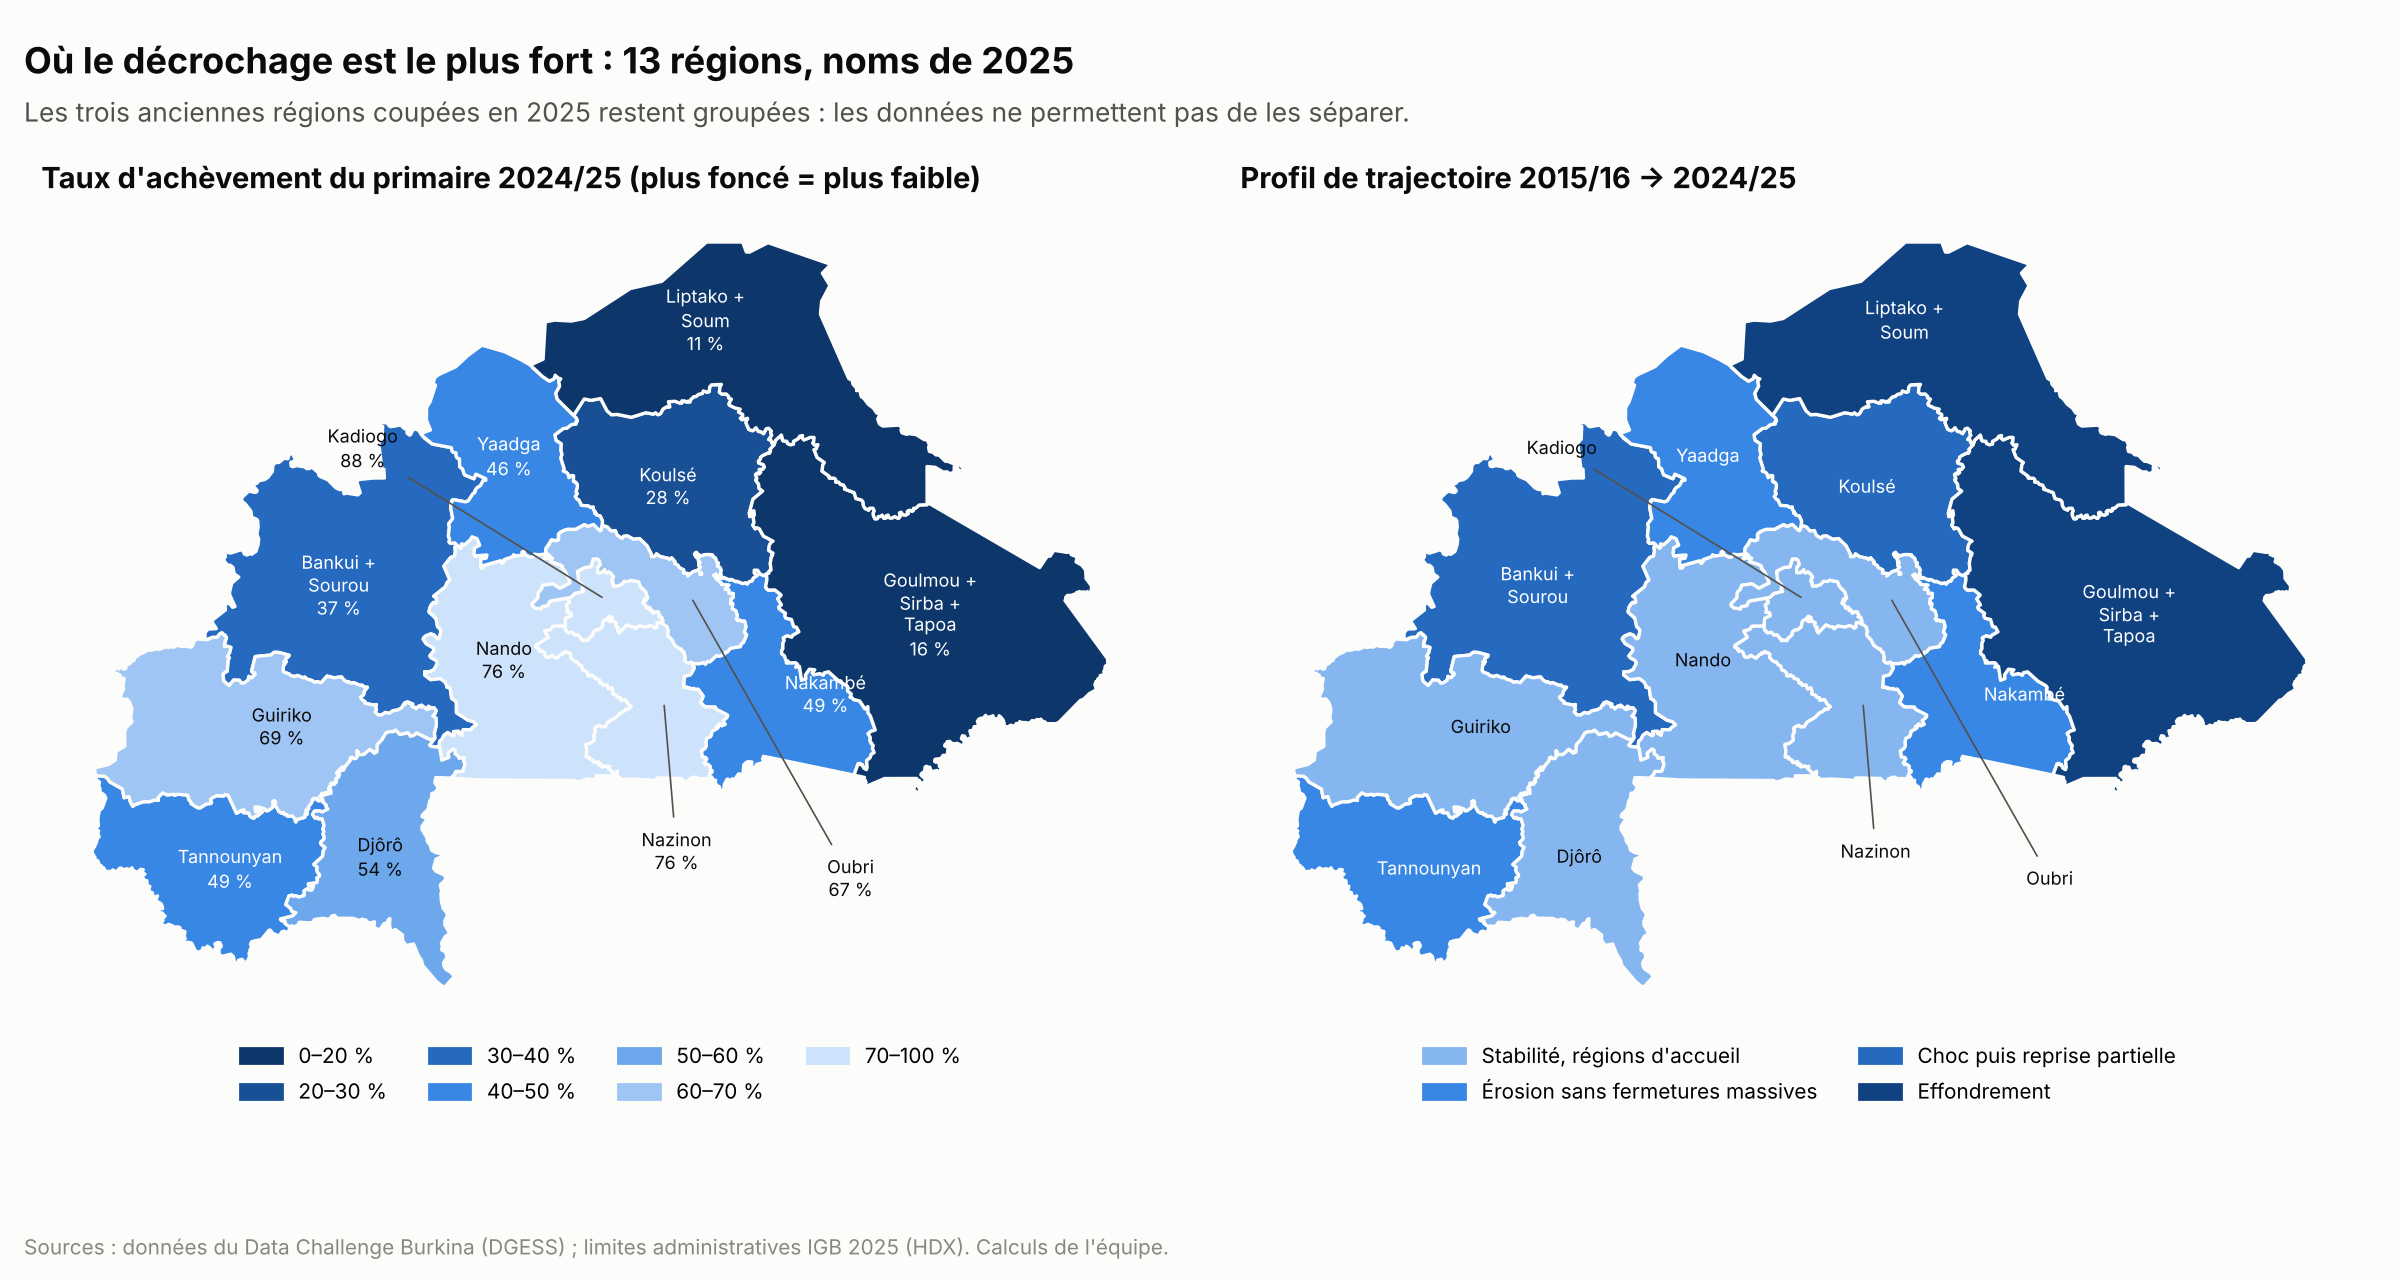

In [25]:
run_carte_13_regions = main
t0 = time.time()
sys.argv = ['carte_13_regions.py', 'data/raw/externe/hdx_cod_ab/geojson/bfa_admin1.geojson', 'data/ref/regions_13_17.csv', 'analyse/']
run_carte_13_regions()
show_figures(t0)